In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.applications import MobileNetV2

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)

(x_train, y_train), (x_test, y_test) = cifar10.load_data()

y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

def preprocess_image(image, label):
    image = tf.image.resize(image, (96, 96))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_dataset = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_dataset = train_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)
train_dataset = train_dataset.shuffle(10000)
train_dataset = train_dataset.batch(32)
train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test_dataset = test_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)
test_dataset = test_dataset.batch(32)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    train_dataset,
    epochs=2,
    validation_data=test_dataset
)

model.save('mobilenetv2_cifar10.keras')

loss, accuracy = model.evaluate(test_dataset)

print("Test Accuracy:", accuracy)



Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 237s 147ms/step - accuracy: 0.7554 - loss: 0.7032 - val_accuracy: 0.7843 - val_loss: 0.6275
Epoch 2/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 288s 184ms/step - accuracy: 0.8065 - loss: 0.5509 - val_accuracy: 0.8070 - val_loss: 0.5652
313/313 ━━━━━━━━━━━━━━━━━━━━ 20s 63ms/step - accuracy: 0.8070 - loss: 0.5652
Test Accuracy: 0.8069999814033508


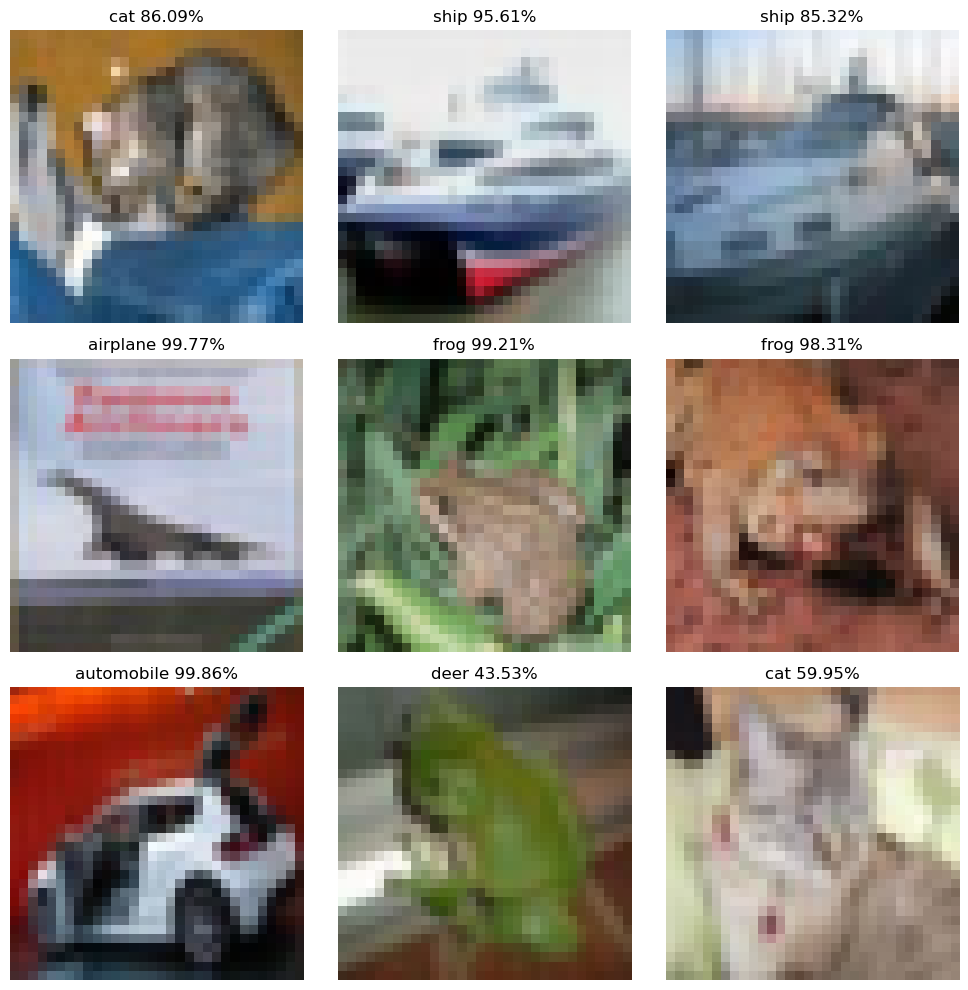

In [3]:
class_names = [
    'airplane','automobile','bird',
    'cat','deer','dog','frog',
    'horse','ship','truck'
]

model = tf.keras.models.load_model('mobilenetv2_cifar10.keras')

plt.figure(figsize=(10, 10))

for i in range(9):
    image = x_test[i]

    processed_image = tf.image.resize(image, (96, 96))
    processed_image = tf.cast(processed_image, tf.float32) / 255.0

    prediction = model.predict(
        tf.expand_dims(processed_image, 0),
        verbose=0
    )

    predicted_class = np.argmax(prediction[0])
    confidence = np.max(prediction[0]) * 100

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(
        f"{class_names[predicted_class]} {confidence:.2f}%"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()